# ⚡ Notebook 04 — XGBoost & LightGBM Multi-Horizon
**Model 1:** XGBoost dengan RandomizedSearchCV + TimeSeriesSplit  
**Model 2:** LightGBM (rekomendasi untuk jurnal Sinta 4 — lebih cepat & sering lebih akurat)

Horizon: **60 menit**, **180 menit**, **360 menit** ke depan

> 💡 **Mengapa LightGBM?**  
> LightGBM menggunakan *leaf-wise* tree growth (vs. *level-wise* XGBoost), sehingga training lebih cepat dan akurasi sering lebih tinggi pada data tabular besar. Menambah LightGBM memperkuat kontribusi paper dengan **3-model comparison**.


In [1]:
# ── CELL 1: Install & Import Library ───────────────────────────
import subprocess, sys
subprocess.run([sys.executable, '-m', 'pip', 'install', '-q', 'lightgbm'], check=False)

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import json, os, warnings, joblib
warnings.filterwarnings('ignore')

import xgboost as xgb
from xgboost import XGBRegressor
import lightgbm as lgb
from lightgbm import LGBMRegressor

from sklearn.model_selection import RandomizedSearchCV, TimeSeriesSplit
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
from scipy.stats import randint, uniform

plt.style.use('seaborn-v0_8-whitegrid')
os.makedirs('models',  exist_ok=True)
os.makedirs('dataset', exist_ok=True)

HORIZONS   = ['60m', '180m', '360m']
TARGET_MAP = {'60m': 'target_60m', '180m': 'target_180m', '360m': 'target_360m'}

print('[OK] Library berhasil diimport')
print(f'  XGBoost   : {xgb.__version__}')
print(f'  LightGBM  : {lgb.__version__}')


[OK] Library berhasil diimport
  XGBoost   : 3.2.0
  LightGBM  : 4.7.0


In [2]:
# ── CELL 2: Fungsi Evaluasi ─────────────────────────────────────
def evaluasi(y_true, y_pred, label=''):
    mae  = mean_absolute_error(y_true, y_pred)
    rmse = np.sqrt(mean_squared_error(y_true, y_pred))
    r2   = r2_score(y_true, y_pred)
    mape = np.mean(np.abs((y_true - y_pred) / (np.abs(y_true) + 1e-8))) * 100
    if label:
        print(f'  [{label}] MAE={mae:.4f}  RMSE={rmse:.4f}  R²={r2:.4f}  MAPE={mape:.2f}%')
    return {'MAE': float(mae), 'RMSE': float(rmse), 'R2': float(r2), 'MAPE': float(mape)}

print('[OK] Fungsi evaluasi siap')


[OK] Fungsi evaluasi siap


In [3]:
# ── CELL 3: Search Space ────────────────────────────────────────
xgb_param_dist = {
    'n_estimators'    : randint(200, 601),
    'max_depth'       : randint(4, 11),
    'learning_rate'   : uniform(0.01, 0.14),   # 0.01 – 0.15
    'subsample'       : uniform(0.6, 0.4),      # 0.6  – 1.0
    'colsample_bytree': uniform(0.6, 0.4),
    'min_child_weight': randint(3, 11),
    'gamma'           : uniform(0, 0.5),
    'reg_alpha'       : uniform(0, 0.5),
    'reg_lambda'      : uniform(0.5, 2.0),
}

lgb_param_dist = {
    'n_estimators'   : randint(200, 601),
    'max_depth'      : randint(4, 11),
    'learning_rate'  : uniform(0.01, 0.14),
    'subsample'      : uniform(0.6, 0.4),
    'colsample_bytree': uniform(0.6, 0.4),
    'min_child_samples': randint(10, 51),
    'reg_alpha'      : uniform(0, 0.5),
    'reg_lambda'     : uniform(0.5, 2.0),
    'num_leaves'     : randint(20, 80),
}

N_ITER = 25
N_CV   = 3

print('=== 🔧 Search Space ===')
print(f'  XGBoost: {len(xgb_param_dist)} params | LightGBM: {len(lgb_param_dist)} params')
print(f'  Iterasi: {N_ITER} | CV folds: {N_CV}')


=== 🔧 Search Space ===
  XGBoost: 9 params | LightGBM: 9 params
  Iterasi: 25 | CV folds: 3


In [4]:
# ── CELL 4: Training XGBoost per Horizon ───────────────────────
xgb_results = {}

for horizon in HORIZONS:
    print(f'\n{"="*55}')
    print(f'  ⚡ XGBoost — Horizon {horizon}')
    print(f'{"="*55}')

    target = TARGET_MAP[horizon]

    df_train = pd.read_csv(f'dataset/data_train_{horizon}.csv', parse_dates=['waktu_pembacaan'])
    df_test  = pd.read_csv(f'dataset/data_test_{horizon}.csv',  parse_dates=['waktu_pembacaan'])
    with open(f'models/feature_cols_{horizon}.json') as f:
        feat_cols = json.load(f)

    X_train = df_train[feat_cols].values.astype(np.float32)
    y_train = df_train[target].values.astype(np.float32)
    X_test  = df_test[feat_cols].values.astype(np.float32)
    y_test  = df_test[target].values.astype(np.float32)

    print(f'  Data: train={len(X_train):,} | test={len(X_test):,} | fitur={len(feat_cols)}')

    # RandomizedSearchCV
    tscv  = TimeSeriesSplit(n_splits=N_CV)
    base  = XGBRegressor(tree_method='hist', random_state=42, n_jobs=-1,
                         eval_metric='rmse', verbosity=0)
    search = RandomizedSearchCV(base, xgb_param_dist, n_iter=N_ITER,
                                cv=tscv, scoring='neg_root_mean_squared_error',
                                n_jobs=-1, random_state=42, verbose=0)
    print('  Mencari hyperparameter terbaik...')
    search.fit(X_train, y_train)

    best_params = search.best_params_
    cv_rmse     = -search.best_score_
    print(f'  Best CV-RMSE : {cv_rmse:.4f}')
    print(f'  Best params  : {best_params}')

    # Final training dengan early stopping
    xgb_final = XGBRegressor(
        **best_params,
        tree_method='hist', random_state=42, n_jobs=-1,
        early_stopping_rounds=30, eval_metric='rmse', verbosity=0
    )
    xgb_final.fit(X_train, y_train,
                  eval_set=[(X_test, y_test)],
                  verbose=False)

    y_pred_train = xgb_final.predict(X_train)
    y_pred_test  = xgb_final.predict(X_test)

    m_train = evaluasi(y_train, y_pred_train, f'XGB Train-{horizon}')
    m_test  = evaluasi(y_test,  y_pred_test,  f'XGB Test-{horizon}')

    # Simpan model
    model_path = f'models/xgb_model_{horizon}.pkl'
    joblib.dump(xgb_final, model_path, compress=3)
    xgb_final.save_model(f'models/xgb_model_{horizon}.json')
    size_mb = os.path.getsize(model_path) / 1e6
    print(f'  [OK] Model disimpan ({size_mb:.1f} MB)')

    # Simpan prediksi
    df_pred = df_test[['waktu_pembacaan', target]].copy()
    df_pred['prediksi_xgb'] = y_pred_test
    df_pred['residual_xgb'] = y_test - y_pred_test
    df_pred.to_csv(f'dataset/prediksi_xgb_{horizon}.csv', index=False)

    xgb_results[horizon] = {
        'best_params'   : best_params,
        'cv_rmse'       : float(cv_rmse),
        'best_iteration': int(xgb_final.best_iteration),
        'train_metrics' : m_train,
        'test_metrics'  : m_test,
        'model_size_mb' : float(size_mb),
    }

with open('models/xgb_metrics_all.json', 'w') as f:
    json.dump(xgb_results, f, indent=2)

print('\n[OK] Semua model XGBoost selesai!')



  ⚡ XGBoost — Horizon 60m
  Data: train=72,240 | test=18,060 | fitur=83
  Mencari hyperparameter terbaik...
  Best CV-RMSE : 2.9430
  Best params  : {'colsample_bytree': np.float64(0.8165791895310264), 'gamma': np.float64(0.3478921996725411), 'learning_rate': np.float64(0.041997003051621955), 'max_depth': 5, 'min_child_weight': 10, 'n_estimators': 259, 'reg_alpha': np.float64(0.1304145874152045), 'reg_lambda': np.float64(2.4925073995158487), 'subsample': np.float64(0.9861677405155175)}
  [XGB Train-60m] MAE=0.3341  RMSE=0.4172  R²=0.9938  MAPE=0.44%
  [XGB Test-60m] MAE=2.4326  RMSE=3.0025  R²=-1.5080  MAPE=3.76%
  [OK] Model disimpan (0.1 MB)

  ⚡ XGBoost — Horizon 180m
  Data: train=72,144 | test=18,036 | fitur=83
  Mencari hyperparameter terbaik...
  Best CV-RMSE : 3.8393
  Best params  : {'colsample_bytree': np.float64(0.9085081386743783), 'gamma': np.float64(0.03702232586704518), 'learning_rate': np.float64(0.06018520199619817), 'max_depth': 4, 'min_child_weight': 6, 'n_estimator

In [5]:
# ── CELL 5: Training LightGBM per Horizon ──────────────────────
lgb_results = {}

for horizon in HORIZONS:
    print(f'\n{"="*55}')
    print(f'  🔥 LightGBM — Horizon {horizon}')
    print(f'{"="*55}')

    target = TARGET_MAP[horizon]

    df_train = pd.read_csv(f'dataset/data_train_{horizon}.csv', parse_dates=['waktu_pembacaan'])
    df_test  = pd.read_csv(f'dataset/data_test_{horizon}.csv',  parse_dates=['waktu_pembacaan'])
    with open(f'models/feature_cols_{horizon}.json') as f:
        feat_cols = json.load(f)

    X_train = df_train[feat_cols].values.astype(np.float32)
    y_train = df_train[target].values.astype(np.float32)
    X_test  = df_test[feat_cols].values.astype(np.float32)
    y_test  = df_test[target].values.astype(np.float32)

    # RandomizedSearchCV
    tscv  = TimeSeriesSplit(n_splits=N_CV)
    base  = LGBMRegressor(random_state=42, n_jobs=-1, verbosity=-1)
    search = RandomizedSearchCV(base, lgb_param_dist, n_iter=N_ITER,
                                cv=tscv, scoring='neg_root_mean_squared_error',
                                n_jobs=-1, random_state=42, verbose=0)
    print('  Mencari hyperparameter terbaik...')
    search.fit(X_train, y_train)

    best_params = search.best_params_
    cv_rmse     = -search.best_score_
    print(f'  Best CV-RMSE : {cv_rmse:.4f}')

    # Final training dengan early stopping
    lgb_final = LGBMRegressor(
        **best_params, random_state=42, n_jobs=-1, verbosity=-1
    )
    lgb_final.fit(
        X_train, y_train,
        eval_set=[(X_test, y_test)],
        callbacks=[lgb.early_stopping(30, verbose=False),
                   lgb.log_evaluation(period=-1)]
    )

    y_pred_train = lgb_final.predict(X_train)
    y_pred_test  = lgb_final.predict(X_test)

    m_train = evaluasi(y_train, y_pred_train, f'LGB Train-{horizon}')
    m_test  = evaluasi(y_test,  y_pred_test,  f'LGB Test-{horizon}')

    # Simpan model
    model_path = f'models/lgb_model_{horizon}.pkl'
    joblib.dump(lgb_final, model_path, compress=3)
    size_mb = os.path.getsize(model_path) / 1e6
    print(f'  [OK] Model disimpan ({size_mb:.1f} MB)')

    # Simpan prediksi
    df_pred = df_test[['waktu_pembacaan', target]].copy()
    df_pred['prediksi_lgb'] = y_pred_test
    df_pred['residual_lgb'] = y_test - y_pred_test
    df_pred.to_csv(f'dataset/prediksi_lgb_{horizon}.csv', index=False)

    lgb_results[horizon] = {
        'best_params'  : best_params,
        'cv_rmse'      : float(cv_rmse),
        'train_metrics': m_train,
        'test_metrics' : m_test,
        'model_size_mb': float(size_mb),
    }

with open('models/lgb_metrics_all.json', 'w') as f:
    json.dump(lgb_results, f, indent=2)

print('\n[OK] Semua model LightGBM selesai!')



  🔥 LightGBM — Horizon 60m
  Mencari hyperparameter terbaik...
  Best CV-RMSE : 2.8610
  [LGB Train-60m] MAE=0.2801  RMSE=0.3514  R²=0.9956  MAPE=0.37%
  [LGB Test-60m] MAE=2.6715  RMSE=3.3766  R²=-2.1720  MAPE=4.14%
  [OK] Model disimpan (0.0 MB)

  🔥 LightGBM — Horizon 180m
  Mencari hyperparameter terbaik...
  Best CV-RMSE : 3.8294
  [LGB Train-180m] MAE=0.4542  RMSE=0.5837  R²=0.9878  MAPE=0.60%
  [LGB Test-180m] MAE=3.5414  RMSE=4.1598  R²=-3.8193  MAPE=5.46%
  [OK] Model disimpan (0.0 MB)

  🔥 LightGBM — Horizon 360m
  Mencari hyperparameter terbaik...
  Best CV-RMSE : 3.6128
  [LGB Train-360m] MAE=0.1886  RMSE=0.2368  R²=0.9980  MAPE=0.25%
  [LGB Test-360m] MAE=3.7952  RMSE=4.5888  R²=-4.8730  MAPE=5.86%
  [OK] Model disimpan (0.3 MB)

[OK] Semua model LightGBM selesai!


In [6]:
# ── CELL 6: Ringkasan Metrik XGBoost vs LightGBM ───────────────
print('=== 📊 Perbandingan XGBoost vs LightGBM ===')
print(f'{"Horizon":<7} {"Model":<10} {"MAE":>8} {"RMSE":>8} {"R²":>8} {"MAPE(%)":>9}')
print('-' * 52)

for horizon in HORIZONS:
    for name, results in [('XGBoost', xgb_results), ('LightGBM', lgb_results)]:
        m = results[horizon]['test_metrics']
        print(f'{horizon:<7} {name:<10} {m["MAE"]:>8.4f} {m["RMSE"]:>8.4f} {m["R2"]:>8.4f} {m["MAPE"]:>9.2f}')
    print()


=== 📊 Perbandingan XGBoost vs LightGBM ===
Horizon Model           MAE     RMSE       R²   MAPE(%)
----------------------------------------------------
60m     XGBoost      2.4326   3.0025  -1.5080      3.76
60m     LightGBM     2.6715   3.3766  -2.1720      4.14

180m    XGBoost      3.4877   4.1139  -3.7136      5.38
180m    LightGBM     3.5414   4.1598  -3.8193      5.46

360m    XGBoost      3.8826   4.6112  -4.9305      5.99
360m    LightGBM     3.7952   4.5888  -4.8730      5.86



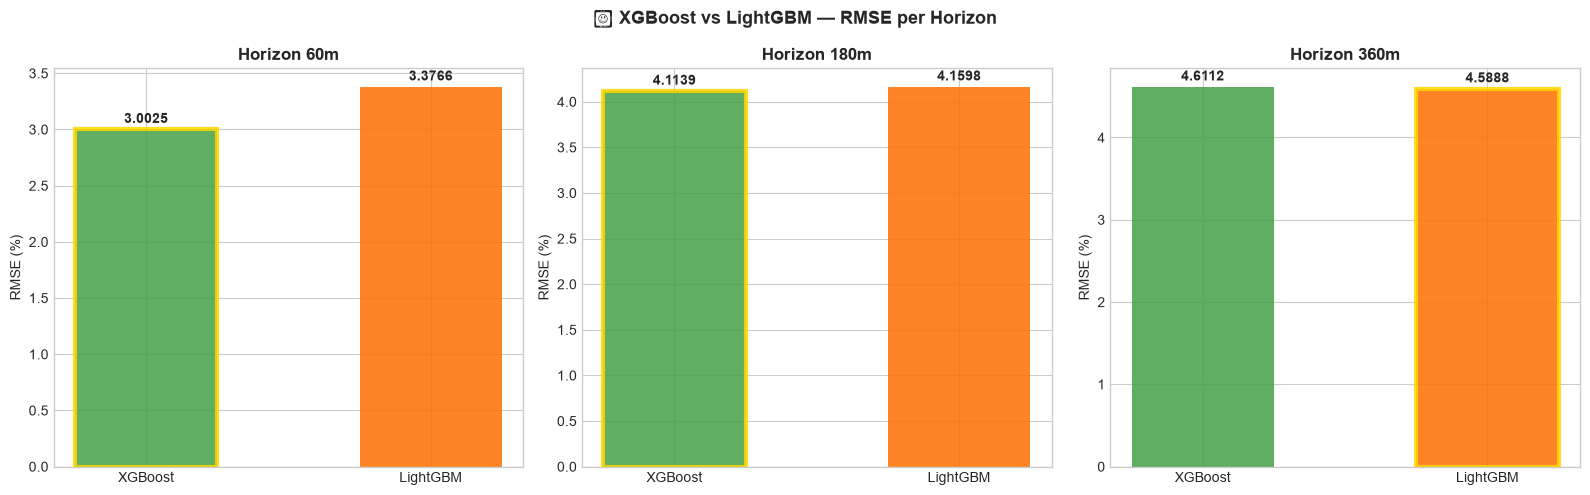

[OK] Plot RMSE XGBoost vs LightGBM disimpan

[OK] Selesai! Lanjut ke → 05_evaluasi_model.ipynb


In [7]:
# ── CELL 7: Plot RMSE per Horizon & Model ──────────────────────
fig, axes = plt.subplots(1, 3, figsize=(16, 5))
fig.suptitle('⚡ XGBoost vs LightGBM — RMSE per Horizon', fontsize=13, fontweight='bold')

for idx, horizon in enumerate(HORIZONS):
    ax = axes[idx]
    models  = ['XGBoost', 'LightGBM']
    rmse_v  = [xgb_results[horizon]['test_metrics']['RMSE'],
               lgb_results[horizon]['test_metrics']['RMSE']]
    colors_m = ['#43A047','#FF6F00']
    bars = ax.bar(models, rmse_v, color=colors_m, alpha=0.85, width=0.5)
    ax.set_title(f'Horizon {horizon}', fontweight='bold')
    ax.set_ylabel('RMSE (%)')
    for bar, v in zip(bars, rmse_v):
        ax.text(bar.get_x()+bar.get_width()/2, v*1.01,
                f'{v:.4f}', ha='center', va='bottom', fontweight='bold', fontsize=10)
    best_idx = int(np.argmin(rmse_v))
    bars[best_idx].set_edgecolor('gold'); bars[best_idx].set_linewidth(3)

plt.tight_layout()
plt.savefig('dataset/plot_xgb_lgb_rmse.png', dpi=150, bbox_inches='tight')
plt.show()
print('[OK] Plot RMSE XGBoost vs LightGBM disimpan')
print('\n[OK] Selesai! Lanjut ke → 05_evaluasi_model.ipynb')
